# SFT Category Analysis — By Diagnosis

Analyse Semantic Fluency Test (SFT) transcripts by mapping each spoken animal token to its biological category, split by diagnosis group (HC, MCI, Dementia).

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from dataloader import TranscriptLoader

sns.set_theme(style="whitegrid")

DIAG_ORDER = ["HC", "MCI", "DEMENTIA"]
DIAG_COLORS = {"HC": "#2ca02c", "MCI": "#1f77b4", "DEMENTIA": "#d62728"}
DIAG_LABELS = {"HC": "Healthy", "MCI": "MCI", "DEMENTIA": "Dementia"}

cat_df = pd.read_csv("categories.csv")
category_lookup = dict(zip(cat_df["answer"], cat_df["category"]))
print(f"Loaded {len(category_lookup)} category mappings")
print("Categories:", sorted(cat_df["category"].unique()))

Loaded 406 category mappings
Categories: ['Amphibian', 'Arachnid', 'Bird', 'Fish', 'Insect', 'Invertebrate', 'Mammal', 'Mythical', 'Reptile', 'Unknown/Other']


## Load SFT Transcripts and Merge Diagnosis Metadata

All available SFT transcripts are loaded so that each diagnosis group has a meaningful sample size.

In [11]:
loader = TranscriptLoader()
all_paths = loader.discover_transcript_files()

sft_paths = [p for p in all_paths if loader.infer_task_from_filename(p.name) == "SFT"]
print(f"Found {len(sft_paths)} SFT transcripts")

frames = [loader.load_transcript(p) for p in sft_paths]
df = pd.concat(frames, ignore_index=True)

metadata = loader.load_metadata()
df = loader.merge_with_metadata(df, metadata)

df["token_clean"] = df["token"].str.strip().str.lower()

df = df[df["diagnosis"].isin(DIAG_ORDER)].copy()
df["diagnosis"] = pd.Categorical(df["diagnosis"], categories=DIAG_ORDER, ordered=True)

print(f"\nTokens per diagnosis group:")
print(df.groupby("diagnosis", observed=True).agg(
    recordings=("recording", "nunique"),
    tokens=("token_clean", "count"),
))
df.head()

Found 91 SFT transcripts

Tokens per diagnosis group:
           recordings  tokens
diagnosis                    
HC                 40     939
MCI                30     590
DEMENTIA           20     334


,start_time,end_time,token,recording,task,recording_number,source_path,diagnosis,age,gender,MMSE,annotator,notes,metadata_recording_number,token_clean
0,4.444,5.188,cheetah,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,cheetah
1,5.82,6.692,lion,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,lion
2,7.292,8.388,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,panda
3,9.596,11.076,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,panda
4,14.588,15.448,elephant,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,elephant


## Map Tokens to Categories

In [12]:
df["category"] = df["token_clean"].map(category_lookup).fillna("Unknown/Other")

unmatched = df.loc[df["category"] == "Unknown/Other", "token_clean"].unique()
print(f"Matched: {(df['category'] != 'Unknown/Other').sum()} / {len(df)} tokens")
if len(unmatched):
    print(f"Unmatched tokens ({len(unmatched)}): {list(unmatched[:20])}")

df[["recording", "diagnosis", "start_time", "token_clean", "category"]].head(15)

Matched: 1842 / 1863 tokens
Unmatched tokens (8): ['?', 'jack', 'ball', 'snow', 'flan', 'unknown?', 'holibert', 'field ?']


,recording,diagnosis,start_time,token_clean,category
0,Process-rec-004,MCI,4.444,cheetah,Mammal
1,Process-rec-004,MCI,5.82,lion,Mammal
2,Process-rec-004,MCI,7.292,panda,Mammal
3,Process-rec-004,MCI,9.596,panda,Mammal
4,Process-rec-004,MCI,14.588,elephant,Mammal
5,Process-rec-004,MCI,15.448,giraffe,Mammal
6,Process-rec-004,MCI,17.596,springbok,Mammal
7,Process-rec-004,MCI,18.844,zebra,Mammal
8,Process-rec-004,MCI,20.284,rhinoceros,Mammal
9,Process-rec-004,MCI,24.764,armadillo,Mammal


## 1. Bar Chart — Category Distribution by Diagnosis

Grouped bars show the mean number of tokens per recording in each category, split by diagnosis.

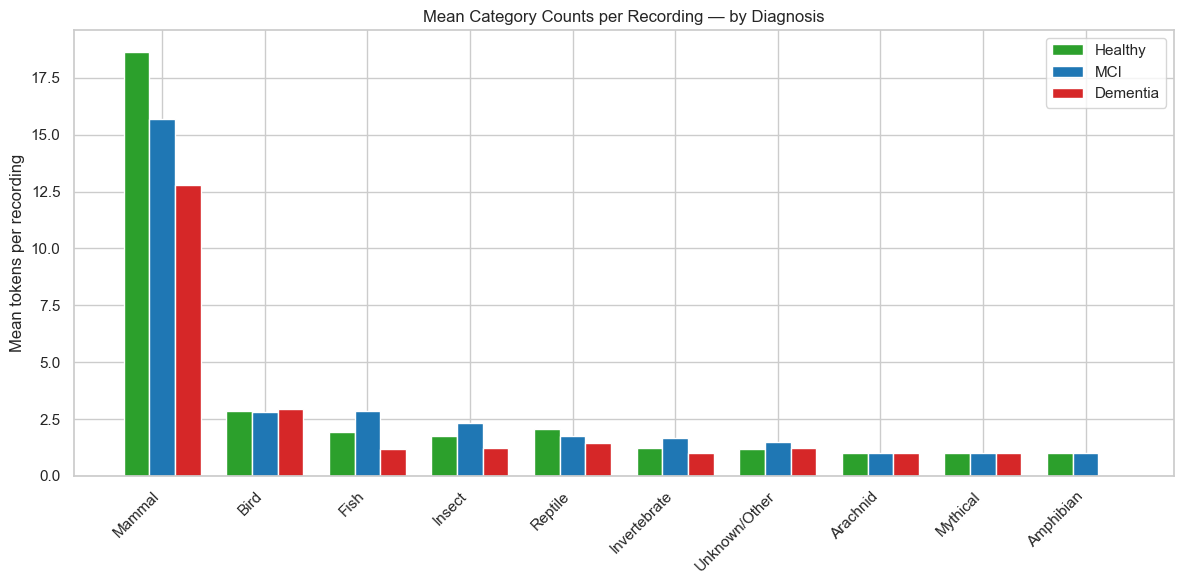

In [13]:
per_rec = (
    df.groupby(["diagnosis", "recording", "category"], observed=True)
    .size()
    .reset_index(name="count")
)
mean_counts = (
    per_rec.groupby(["diagnosis", "category"], observed=True)["count"]
    .mean()
    .reset_index(name="mean_count")
)

cat_order = (
    mean_counts.groupby("category")["mean_count"].sum()
    .sort_values(ascending=False).index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(cat_order))
width = 0.25

for i, diag in enumerate(DIAG_ORDER):
    subset = mean_counts[mean_counts["diagnosis"] == diag].set_index("category")
    vals = [subset.loc[c, "mean_count"] if c in subset.index else 0 for c in cat_order]
    ax.bar(x + i * width, vals, width, label=DIAG_LABELS[diag], color=DIAG_COLORS[diag])

ax.set_xticks(x + width)
ax.set_xticklabels(cat_order, rotation=45, ha="right")
ax.set_ylabel("Mean tokens per recording")
ax.set_title("Mean Category Counts per Recording — by Diagnosis")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Stacked Bar Chart — Categories per Recording (coloured by diagnosis)

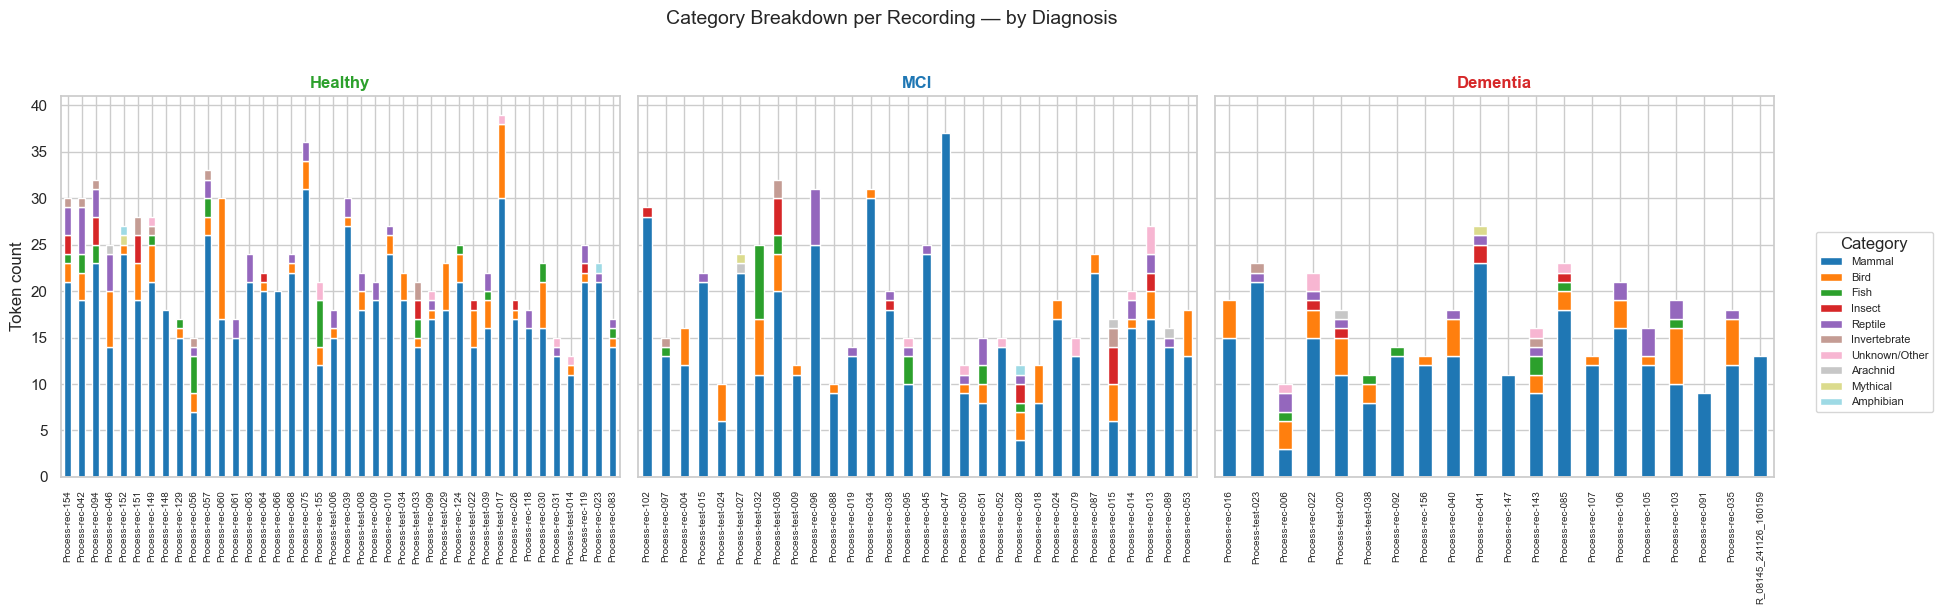

In [14]:
rec_diag = df.groupby("recording", observed=True)["diagnosis"].first()

cross = pd.crosstab(df["recording"], df["category"])
cross = cross[cat_order]
cross["diagnosis"] = cross.index.map(rec_diag)
cross = cross.sort_values("diagnosis")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, diag in zip(axes, DIAG_ORDER):
    group = cross[cross["diagnosis"] == diag].drop(columns="diagnosis")
    if group.empty:
        ax.set_title(f"{DIAG_LABELS[diag]} (no data)")
        continue
    group.plot.bar(stacked=True, ax=ax, colormap="tab20", legend=False)
    ax.set_title(DIAG_LABELS[diag], color=DIAG_COLORS[diag], fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90, labelsize=7)

axes[0].set_ylabel("Token count")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Category", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=8)
fig.suptitle("Category Breakdown per Recording — by Diagnosis", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Average Number of Distinct Categories per Participant — by Diagnosis

Average distinct categories per participant:
          mean   std  count
Healthy   3.30  1.16     40
MCI       2.83  1.23     30
Dementia  3.15  1.50     20



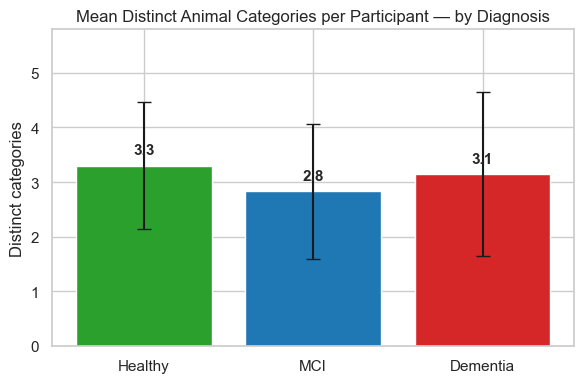

In [20]:
cats_per_rec = (
    df.groupby(["diagnosis", "recording"], observed=True)["category"]
    .nunique()
    .reset_index(name="n_categories")
)
avg_cats = (
    cats_per_rec.groupby("diagnosis", observed=True)["n_categories"]
    .agg(["mean", "std", "count"])
    .reindex(DIAG_ORDER)
)
avg_cats.index = [DIAG_LABELS[d] for d in avg_cats.index]
print("Average distinct categories per participant:")
print(avg_cats.round(2))
print()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    avg_cats.index,
    avg_cats["mean"],
    yerr=avg_cats["std"],
    capsize=5,
    color=[DIAG_COLORS[d] for d in DIAG_ORDER],
    edgecolor="white",
)
for bar, val in zip(bars, avg_cats["mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{val:.1f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("Distinct categories")
ax.set_title("Mean Distinct Animal Categories per Participant — by Diagnosis")
ax.set_ylim(0, avg_cats["mean"].max() + avg_cats["std"].max() + 1)
plt.tight_layout()
plt.show()

## 3. Category Proportion Heatmap — by Diagnosis

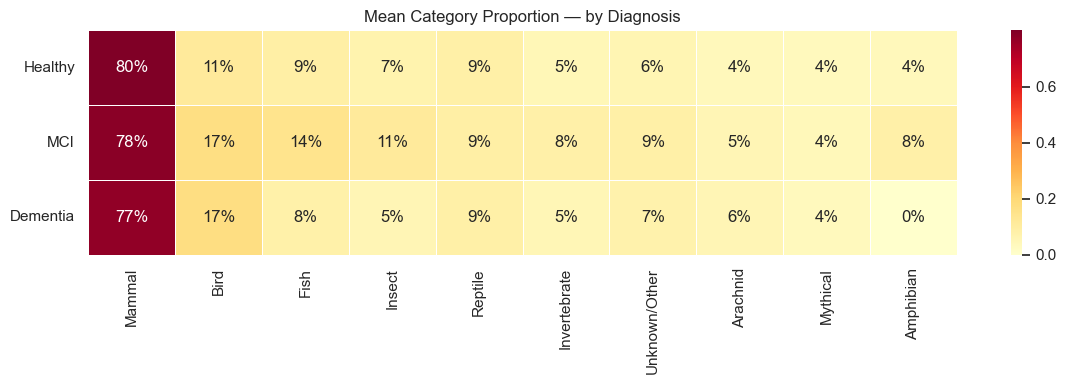

In [15]:
mean_props = (
    per_rec.assign(
        total=per_rec.groupby(["diagnosis", "recording"], observed=True)["count"].transform("sum")
    )
    .assign(prop=lambda x: x["count"] / x["total"])
    .groupby(["diagnosis", "category"], observed=True)["prop"]
    .mean()
    .reset_index()
    .pivot(index="diagnosis", columns="category", values="prop")
    .reindex(DIAG_ORDER)
    .fillna(0)
)
mean_props = mean_props[cat_order]
mean_props.index = [DIAG_LABELS[d] for d in mean_props.index]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(
    mean_props,
    annot=True,
    fmt=".0%",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Mean Category Proportion — by Diagnosis")
ax.set_ylabel("")
ax.set_xlabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Temporal Category Sequence — One per Diagnosis

Each subplot shows a representative recording from each diagnosis group. Dots are coloured by animal category; clusters reveal semantic grouping patterns.

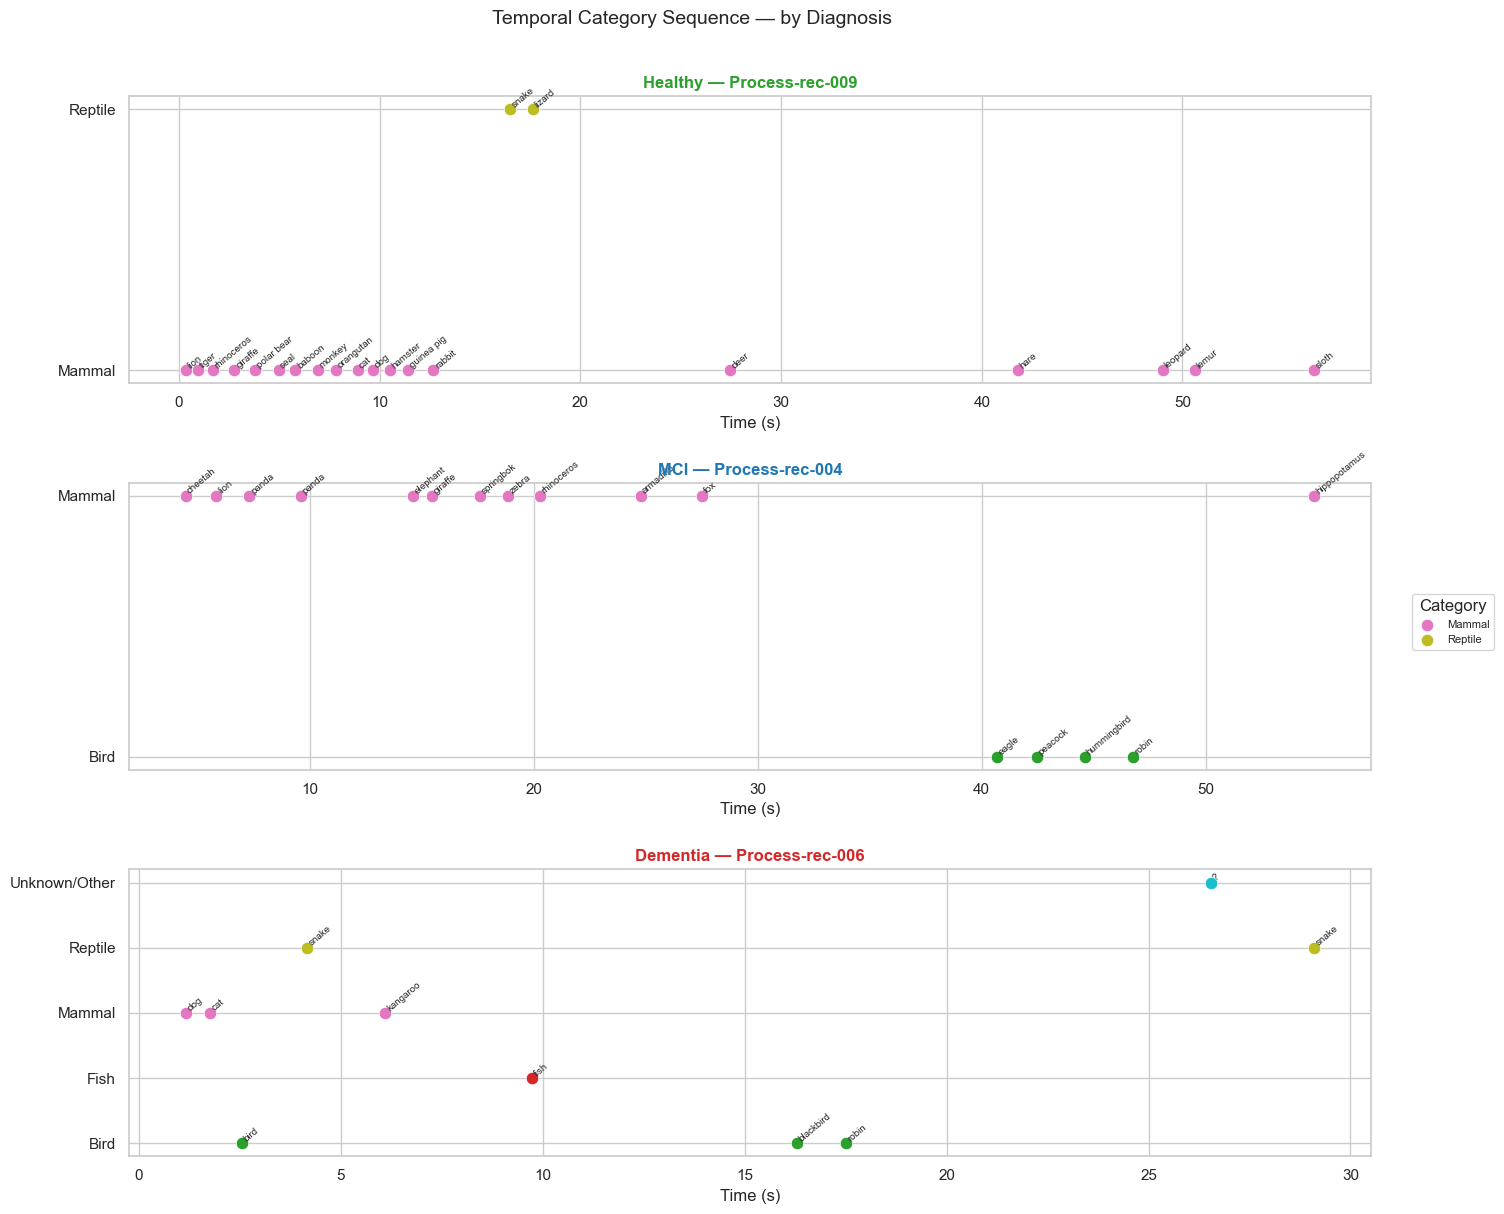

In [19]:
all_cats = sorted(df["category"].unique())
cat_palette = dict(zip(all_cats, sns.color_palette("tab10", len(all_cats))))

fig, axes = plt.subplots(len(DIAG_ORDER), 1, figsize=(14, 4 * len(DIAG_ORDER)), sharex=False)

for ax, diag in zip(axes, DIAG_ORDER):
    group_recs = df[df["diagnosis"] == diag]["recording"].unique()
    if len(group_recs) == 0:
        ax.set_title(f"{DIAG_LABELS[diag]} — no data")
        continue
    sample_rec = group_recs[0]
    sample = df[df["recording"] == sample_rec].sort_values("start_time").reset_index(drop=True)

    for cat in all_cats:
        mask = sample["category"] == cat
        if mask.sum() == 0:
            continue
        ax.scatter(
            sample.loc[mask, "start_time"],
            [cat] * mask.sum(),
            color=cat_palette[cat],
            s=80,
            label=cat,
            edgecolors="white",
            linewidth=0.5,
            zorder=3,
        )

    for _, row in sample.iterrows():
        ax.annotate(
            row["token_clean"],
            (row["start_time"], row["category"]),
            fontsize=7,
            rotation=40,
            ha="left",
            va="bottom",
        )

    ax.set_title(f"{DIAG_LABELS[diag]} — {sample_rec}", color=DIAG_COLORS[diag], fontweight="bold")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Category", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=8)
fig.suptitle("Temporal Category Sequence — by Diagnosis", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Category Switching Analysis — by Diagnosis

A *switch* occurs when consecutive tokens belong to different categories. Higher switch rates may reflect stronger executive function and flexible retrieval strategies.

/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_11982/2124853610.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_11982/2124853610.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_11982/2124853610.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_11982/2124853610.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

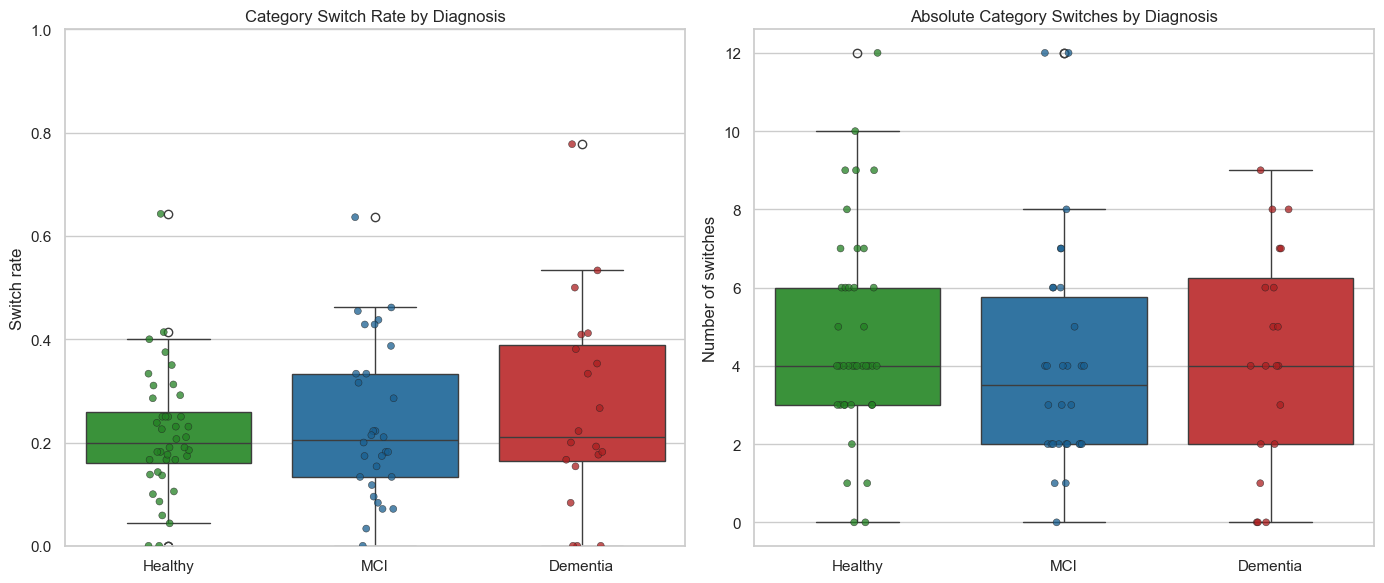

Mean switch rate per group:
               mean       std  count
diagnosis                           
Healthy    0.216217  0.120918     40
MCI        0.239200  0.152708     30
Dementia   0.267126  0.198684     20


In [15]:
def compute_switch_rate(group):
    group = group.sort_values("start_time")
    cats = group["category"].values
    if len(cats) < 2:
        return pd.Series({"switches": 0, "total_transitions": 0, "switch_rate": np.nan})
    switches = sum(a != b for a, b in zip(cats[:-1], cats[1:]))
    total = len(cats) - 1
    return pd.Series({"switches": switches, "total_transitions": total, "switch_rate": switches / total})

switch_df = (
    df.groupby("recording", observed=True)
    .apply(compute_switch_rate, include_groups=False)
    .reset_index()
)
switch_df["diagnosis"] = switch_df["recording"].map(
    df.groupby("recording", observed=True)["diagnosis"].first()
)
switch_df["diagnosis"] = pd.Categorical(switch_df["diagnosis"], categories=DIAG_ORDER, ordered=True)

# Slightly darker colors for dots so they stand out
import colorsys
from matplotlib.colors import to_rgb

def _darken(color, amount=0.85):
    r, g, b = to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    l = max(0, min(1, l * amount))
    return colorsys.hls_to_rgb(h, l, s)

_strip_palette = {d: _darken(DIAG_COLORS[d], amount=0.80) for d in DIAG_ORDER}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=switch_df, x="diagnosis", y="switch_rate",
    order=DIAG_ORDER, palette=DIAG_COLORS, ax=axes[0],
)
sns.stripplot(
    data=switch_df, x="diagnosis", y="switch_rate",
    order=DIAG_ORDER, palette=_strip_palette, ax=axes[0],
    size=5, alpha=0.75, jitter=True,
    edgecolor="#222", linewidth=0.4,
)
axes[0].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
axes[0].set_ylabel("Switch rate")
axes[0].set_xlabel("")
axes[0].set_title("Category Switch Rate by Diagnosis")
axes[0].set_ylim(0, 1)

sns.boxplot(
    data=switch_df, x="diagnosis", y="switches",
    order=DIAG_ORDER, palette=DIAG_COLORS, ax=axes[1],
)
sns.stripplot(
    data=switch_df, x="diagnosis", y="switches",
    order=DIAG_ORDER, palette=_strip_palette, ax=axes[1],
    size=5, alpha=0.75, jitter=True,
    edgecolor="#222", linewidth=0.4,
)
axes[1].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
axes[1].set_ylabel("Number of switches")
axes[1].set_xlabel("")
axes[1].set_title("Absolute Category Switches by Diagnosis")

plt.tight_layout()
plt.show()

print("Mean switch rate per group:")
print(switch_df.groupby("diagnosis", observed=True)["switch_rate"].agg(["mean", "std", "count"]).rename(
    index=DIAG_LABELS
))

## 6. Pie Charts — Category Proportions by Diagnosis

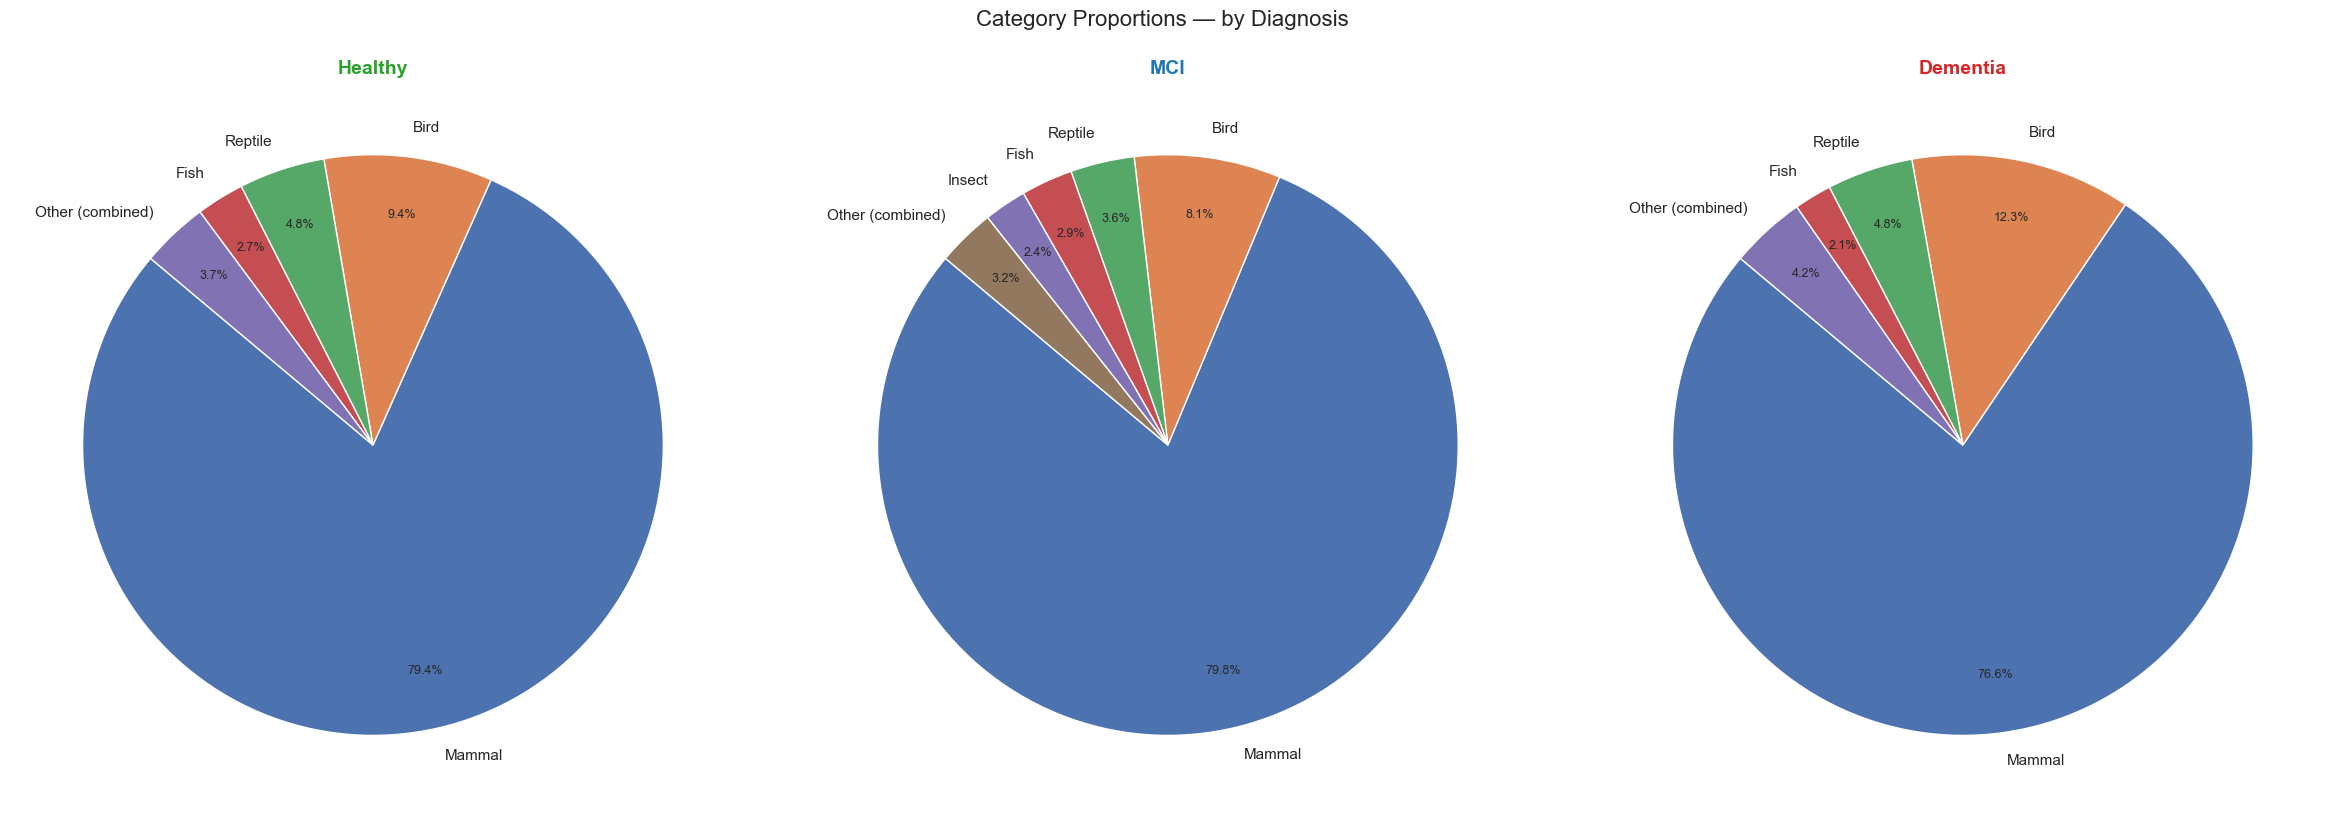

In [14]:
fig, axes = plt.subplots(1, len(DIAG_ORDER), figsize=(8 * len(DIAG_ORDER), 8))

for ax, diag in zip(axes, DIAG_ORDER):
    sub = df[df["diagnosis"] == diag]
    if sub.empty:
        ax.set_title(f"{DIAG_LABELS[diag]} — no data")
        continue
    cat_totals = sub["category"].value_counts()

    threshold = 0.02 * len(sub)
    main_cats = cat_totals[cat_totals >= threshold].copy()
    other_sum = cat_totals[cat_totals < threshold].sum()
    if other_sum > 0:
        main_cats["Other (combined)"] = other_sum

    wedges, texts, autotexts = ax.pie(
        main_cats,
        labels=main_cats.index,
        autopct="%1.1f%%",
        startangle=140,
        pctdistance=0.8,
    )
    for t in autotexts:
        t.set_fontsize(9)
    ax.set_title(DIAG_LABELS[diag], color=DIAG_COLORS[diag], fontweight="bold", fontsize=14)

fig.suptitle("Category Proportions — by Diagnosis", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()